# Nominal vs Real Exchange Rate: Decomposition and Comparison

## Purpose

Most analyses of currency risk in developing countries focus on **nominal exchange rate** devaluations. These events look dramatic but overstate the actual risk for projects with inflation-adjusted revenues. This notebook decomposes the nominal exchange rate into:

1. **PPP-expected depreciation** (baked into forward rates): the gradual nominal slide driven by the inflation differential between the local country and the US. Under covered interest rate parity, forward rates price in this expected depreciation.

2. **Real exchange rate** movement (the residual): what remains after stripping out inflation. This is what actually matters for projects whose local-currency revenues grow with inflation.

The key identity:

$$\text{Nominal FX change} = \text{Real FX change} \times \frac{P_{\text{local}}(t)}{P_{\text{local}}(t_0)}$$

The PPP-expected path represents where the nominal exchange rate *should* be if only inflation differentials drove the exchange rate:

$$\text{PPP-expected}(t) = 100 \times \frac{\text{CPI}_{\text{US}}(t)/\text{CPI}_{\text{US}}(t_0)}{\text{CPI}_{\text{local}}(t)/\text{CPI}_{\text{local}}(t_0)}$$

This is exactly what the forward rate would imply under covered interest parity with Fisher-equation interest rates and equal real rates across countries.

In [1]:
%run ../source/data_analysis_functions.py
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

## 1. Build decomposition data

For each country, we construct three normalised indices (all starting at 100):
- **Nominal FX index**: `1/X` (USD per LCU), normalised
- **Real FX index**: `H = P/X`, normalised (this is `fx_index` from the main analysis)
- **PPP-expected path**: the forward-implied nominal path based on cumulative inflation differentials

In [2]:
decomp = build_decomposition_df(start="2000-01-01", end="2023-12-31")
print(f"Shape: {decomp.shape}")
print(f"Countries: {decomp['country'].nunique()}")
print(f"Year range: {decomp['year'].min()}-{decomp['year'].max()}")
decomp.head(10)

No valid data for STP
No valid data for SSD
Shape: (1177, 7)
Countries: 52
Year range: 2000-2023


,country,year,nominal_fx_index,nominal_fx_baseline,real_fx_index,real_fx_baseline,ppp_expected_path
0,AGO,2006,54.162001,62.910959,190.712770,139.401448,31.434439
1,AGO,2007,56.746187,54.260197,239.141575,167.229763,26.940469
2,AGO,2008,58.016793,54.194878,278.785009,200.701820,24.328092
3,AGO,2009,54.872053,54.747934,294.147693,232.070651,21.742307
4,AGO,2010,47.363765,54.232160,286.127866,257.782983,19.640578
5,AGO,2011,46.340703,52.667900,328.660000,285.372429,17.150589
6,AGO,2012,45.618889,50.442441,357.305698,309.005253,15.818122
7,AGO,2013,45.100256,47.859133,373.476681,327.943588,15.156391
8,AGO,2014,44.281727,45.741068,418.339923,352.782034,13.469541
9,AGO,2015,36.255135,43.519342,384.301230,372.416706,12.022920


## 2. Event detection: Nominal vs Real

We apply the same window-based event detection (10% trigger, 10% end threshold) to both the nominal and real exchange rate indices. This allows a direct comparison of how many events are detected, their severity, and their duration.

In [3]:
# Prepare nominal FX dataframe with column names expected by identify_events
nominal_df = decomp[['country', 'year', 'nominal_fx_index', 'nominal_fx_baseline']].copy()
nominal_df = nominal_df.rename(columns={
    'nominal_fx_index': 'fx_index',
    'nominal_fx_baseline': 'baseline'
})
nominal_df['nominal_fx'] = nominal_df['fx_index']  # required by compute_terminal_residuals

events_nominal, df_nominal = identify_events(
    nominal_df.copy(), trigger_threshold=0.1, end_threshold=0.1
)

print("=== NOMINAL FX EVENTS ===")
print(f"Events detected: {len(events_nominal)}")
print(f"Avg peak devaluation: {events_nominal['Peak_Devaluation'].mean():.1f}%")
print(f"Avg duration: {events_nominal['Duration'].mean():.1f} years")
print(f"Avg drawdown area: {events_nominal['Drawdown_Area'].mean():.1f}")
print(f"Total drawdown area: {events_nominal['Drawdown_Area'].sum():.0f}")

=== NOMINAL FX EVENTS ===
Events detected: 68
Avg peak devaluation: -46.5%
Avg duration: 13.5 years
Avg drawdown area: -590.6
Total drawdown area: -40162


In [4]:
# Prepare real FX dataframe
real_df = decomp[['country', 'year', 'real_fx_index', 'real_fx_baseline']].copy()
real_df = real_df.rename(columns={
    'real_fx_index': 'fx_index',
    'real_fx_baseline': 'baseline'
})
real_df['nominal_fx'] = decomp['nominal_fx_index'].values

events_real, df_real = identify_events(
    real_df.copy(), trigger_threshold=0.1, end_threshold=0.1
)

print("=== REAL FX EVENTS ===")
print(f"Events detected: {len(events_real)}")
print(f"Avg peak devaluation: {events_real['Peak_Devaluation'].mean():.1f}%")
print(f"Avg duration: {events_real['Duration'].mean():.1f} years")
print(f"Avg drawdown area: {events_real['Drawdown_Area'].mean():.1f}")
print(f"Total drawdown area: {events_real['Drawdown_Area'].sum():.0f}")

=== REAL FX EVENTS ===
Events detected: 67
Avg peak devaluation: -24.8%
Avg duration: 6.0 years
Avg drawdown area: -110.5
Total drawdown area: -7402


In [5]:
# Side-by-side comparison table
comparison = pd.DataFrame({
    'Metric': [
        'Number of events',
        'Avg peak devaluation (%)',
        'Median peak devaluation (%)',
        'Avg duration (years)',
        'Avg drawdown area (%-years)',
        'Total drawdown area',
        'Countries affected',
    ],
    'Nominal FX': [
        len(events_nominal),
        f"{events_nominal['Peak_Devaluation'].mean():.1f}",
        f"{events_nominal['Peak_Devaluation'].median():.1f}",
        f"{events_nominal['Duration'].mean():.1f}",
        f"{events_nominal['Drawdown_Area'].mean():.1f}",
        f"{events_nominal['Drawdown_Area'].sum():.0f}",
        events_nominal['Country'].nunique(),
    ],
    'Real FX': [
        len(events_real),
        f"{events_real['Peak_Devaluation'].mean():.1f}",
        f"{events_real['Peak_Devaluation'].median():.1f}",
        f"{events_real['Duration'].mean():.1f}",
        f"{events_real['Drawdown_Area'].mean():.1f}",
        f"{events_real['Drawdown_Area'].sum():.0f}",
        events_real['Country'].nunique(),
    ]
})
print("=== EVENT COMPARISON: NOMINAL vs REAL ===")
print(comparison.to_string(index=False))

=== EVENT COMPARISON: NOMINAL vs REAL ===
                     Metric Nominal FX Real FX
           Number of events         68      67
   Avg peak devaluation (%)      -46.5   -24.8
Median peak devaluation (%)      -23.1   -19.7
       Avg duration (years)       13.5     6.0
Avg drawdown area (%-years)     -590.6  -110.5
        Total drawdown area     -40162   -7402
         Countries affected         49      47


## 3. Terminal liability comparison

We apply the same 15-year rolling window terminal residual computation to both the nominal and real exchange rate indices. The nominal terminal liability represents what an unhedged project would face. The real terminal liability represents what a project with inflation-adjusted revenues would face.

In [6]:
# Terminal residuals: nominal
residuals_nominal = compute_terminal_residuals(
    nominal_df.copy(), years=15, discount_rate=0.1, window_mode="rolling"
)

# Terminal residuals: real
residuals_real = compute_terminal_residuals(
    real_df.copy(), years=15, discount_rate=0.1, window_mode="rolling"
)

print("=== TERMINAL LIABILITY COMPARISON (15-year windows, 10% discount rate) ===")
print(f"\nNominal FX:")
print(f"  Windows: {len(residuals_nominal)}")
print(f"  Expected annual premium: {residuals_nominal['loss'].mean()*100:.2f}% of debt stock")
print(f"  Probability of loss: {(residuals_nominal['loss'] < 0).mean()*100:.0f}%")
print(f"  Mean net PV: {residuals_nominal['net_pv_by_debt_stock'].mean()*100:.2f}%")

print(f"\nReal FX:")
print(f"  Windows: {len(residuals_real)}")
print(f"  Expected annual premium: {residuals_real['loss'].mean()*100:.2f}% of debt stock")
print(f"  Probability of loss: {(residuals_real['loss'] < 0).mean()*100:.0f}%")
print(f"  Mean net PV: {residuals_real['net_pv_by_debt_stock'].mean()*100:.2f}%")

if residuals_real['loss'].mean() != 0:
    print(f"\nNominal/Real loss ratio: {residuals_nominal['loss'].mean() / residuals_real['loss'].mean():.1f}x")
print("\nInterpretation: The nominal terminal liability is much larger because it includes")
print("the expected depreciation from inflation differentials, which is already priced")
print("into forward rates and compensated by inflation-adjusted revenues.")

=== TERMINAL LIABILITY COMPARISON (15-year windows, 10% discount rate) ===

Nominal FX:
  Windows: 452
  Expected annual premium: -1.67% of debt stock
  Probability of loss: 68%
  Mean net PV: -1.06%

Real FX:
  Windows: 452
  Expected annual premium: -0.19% of debt stock
  Probability of loss: 16%
  Mean net PV: 3.86%

Nominal/Real loss ratio: 8.8x

Interpretation: The nominal terminal liability is much larger because it includes
the expected depreciation from inflation differentials, which is already priced
into forward rates and compensated by inflation-adjusted revenues.


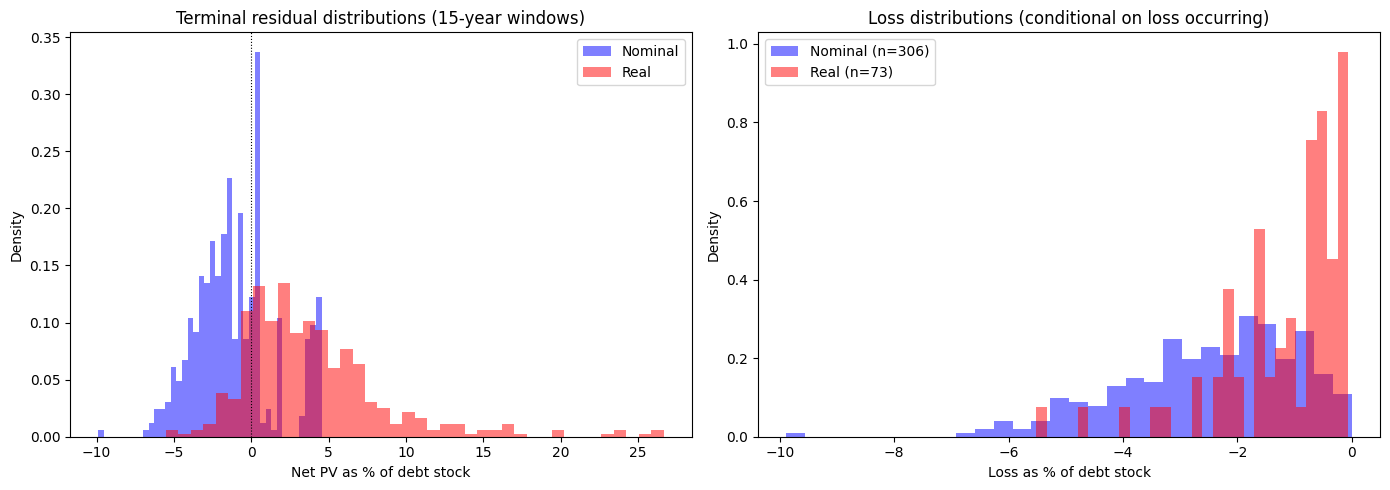

In [7]:
# Distribution comparison plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Terminal residual distributions
axes[0].hist(residuals_nominal['net_pv_by_debt_stock'] * 100, bins=40, alpha=0.5,
             label='Nominal', color='blue', density=True)
axes[0].hist(residuals_real['net_pv_by_debt_stock'] * 100, bins=40, alpha=0.5,
             label='Real', color='red', density=True)
axes[0].axvline(x=0, color='black', linestyle=':', linewidth=0.8)
axes[0].set_xlabel('Net PV as % of debt stock')
axes[0].set_ylabel('Density')
axes[0].set_title('Terminal residual distributions (15-year windows)')
axes[0].legend()

# Loss-only distributions
nom_losses = residuals_nominal[residuals_nominal['loss'] < 0]['loss'] * 100
real_losses = residuals_real[residuals_real['loss'] < 0]['loss'] * 100
axes[1].hist(nom_losses, bins=30, alpha=0.5, label=f'Nominal (n={len(nom_losses)})',
             color='blue', density=True)
axes[1].hist(real_losses, bins=30, alpha=0.5, label=f'Real (n={len(real_losses)})',
             color='red', density=True)
axes[1].set_xlabel('Loss as % of debt stock')
axes[1].set_ylabel('Density')
axes[1].set_title('Loss distributions (conditional on loss occurring)')
axes[1].legend()

plt.tight_layout()
plt.savefig('../output/terminal_liability_nominal_vs_real.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Expected depreciation priced into forward rates

Under covered interest rate parity, a forward contract prices in the expected depreciation driven by the interest rate differential, which by the Fisher equation approximately equals the inflation differential. We can compute the PPP-expected path for each country and apply the same terminal residual analysis to quantify what this "cost of the forward" amounts to.

The PPP-expected path systematically declines for high-inflation countries, reflecting the predictable and priced-in component of nominal depreciation. The key comparison:

| Component | Measures | For the project |
|-----------|----------|-----------------|
| **Nominal net PV** | Total FX impact (what most people fear) | Irrelevant if revenues adjust with inflation |
| **PPP-expected net PV** | Expected depreciation (cost of forward cover) | The price of hedging via forwards |
| **Real net PV** | Residual risk beyond inflation adjustment | What actually affects debt service capacity |

In [8]:
# Build PPP-expected path as an "index" and compute its terminal residuals
ppp_df = decomp[['country', 'year', 'ppp_expected_path']].copy()
ppp_df = ppp_df.rename(columns={'ppp_expected_path': 'fx_index'})
ppp_df['baseline'] = ppp_df.groupby('country')['fx_index'].transform(
    lambda x: x.rolling(window=5, min_periods=5).mean()
)
ppp_df['nominal_fx'] = ppp_df['fx_index']
ppp_df = ppp_df.dropna()

residuals_ppp = compute_terminal_residuals(
    ppp_df.copy(), years=15, discount_rate=0.1, window_mode="rolling"
)

print("=== TERMINAL LIABILITY BY COMPONENT (15-year windows, 10% discount rate) ===")
print(f"\n{'Component':<45} {'Mean net PV':>12} {'E[loss]':>12} {'P(loss)':>10}")
print("-" * 82)
print(f"{'Nominal (total cost if unhedged)':<45} "
      f"{residuals_nominal['net_pv_by_debt_stock'].mean()*100:>11.2f}% "
      f"{residuals_nominal['loss'].mean()*100:>11.2f}% "
      f"{(residuals_nominal['loss']<0).mean()*100:>9.0f}%")
print(f"{'PPP-expected (cost of forward cover)':<45} "
      f"{residuals_ppp['net_pv_by_debt_stock'].mean()*100:>11.2f}% "
      f"{residuals_ppp['loss'].mean()*100:>11.2f}% "
      f"{(residuals_ppp['loss']<0).mean()*100:>9.0f}%")
print(f"{'Real (residual risk, our insurance)':<45} "
      f"{residuals_real['net_pv_by_debt_stock'].mean()*100:>11.2f}% "
      f"{residuals_real['loss'].mean()*100:>11.2f}% "
      f"{(residuals_real['loss']<0).mean()*100:>9.0f}%")

print(f"\n--- Interpretation ---")
print(f"The PPP-expected path captures the systematic, predictable depreciation driven")
print(f"by inflation differentials. This component is priced into forward rates and")
print(f"would be the cost of hedging nominal FX risk via forwards.")
print(f"")
print(f"The real component is the unpredictable residual: with a loss probability of only")
print(f"{(residuals_real['loss']<0).mean()*100:.0f}% and expected loss of "
      f"{residuals_real['loss'].mean()*100:.2f}% of debt stock, it is affordable to insure.")
print(f"In contrast, hedging the full nominal risk via forwards would cost significantly more,")
print(f"reflecting the large inflation differential that is already compensated by")
print(f"inflation-adjusted tariff revenues.")

=== TERMINAL LIABILITY BY COMPONENT (15-year windows, 10% discount rate) ===

Component                                      Mean net PV      E[loss]    P(loss)
----------------------------------------------------------------------------------
Nominal (total cost if unhedged)                    -1.06%       -1.67%        68%
PPP-expected (cost of forward cover)                -2.18%       -2.29%        87%
Real (residual risk, our insurance)                  3.86%       -0.19%        16%

--- Interpretation ---
The PPP-expected path captures the systematic, predictable depreciation driven
by inflation differentials. This component is priced into forward rates and
would be the cost of hedging nominal FX risk via forwards.

The real component is the unpredictable residual: with a loss probability of only
16% and expected loss of -0.19% of debt stock, it is affordable to insure.
In contrast, hedging the full nominal risk via forwards would cost significantly more,
reflecting the large inf

## 5. Case studies

We examine three countries with notable recent devaluation events. Each illustrates the same point: despite dramatic nominal devaluations, the real exchange rate effect was considerably more manageable because local inflation eventually compensates for the nominal slide.

- **Nigeria**: The naira experienced chronic nominal depreciation, culminating in the June 2023 float. High domestic inflation (15-30% p.a.) means the forward rate already prices in substantial annual depreciation.
- **Kenya**: The shilling depreciated ~50% nominally against the USD between 2010-2023. Yet with moderate inflation (~7%), the real exchange rate remained stable enough that no real devaluation events are detected.
- **Ghana**: The cedi lost over 95% of its nominal value against the USD since 2000, but very high inflation (often 20-50%) meant the real exchange rate impact was far more contained.

In [9]:
def plot_case_study(decomp, country_code, country_name, events_nom, events_re, save=True):
    """Plot nominal vs real FX decomposition for a single country."""
    cd = decomp[decomp['country'] == country_code].sort_values('year')
    if len(cd) == 0:
        print(f"No data for {country_code}")
        return

    fig, axes = plt.subplots(2, 1, figsize=(11, 9), height_ratios=[2, 1])

    # --- Top panel: index levels ---
    ax = axes[0]
    ax.plot(cd['year'], cd['nominal_fx_index'], 'b-', linewidth=2,
            label='Nominal FX index (USD/LCU)')
    ax.plot(cd['year'], cd['real_fx_index'], 'r-', linewidth=2,
            label=r'Real FX index ($H = P/X$)')
    ax.plot(cd['year'], cd['ppp_expected_path'], 'g--', linewidth=1.5,
            label='PPP-expected path (forward-implied)')

    ax.axhline(y=100, color='gray', linestyle=':', alpha=0.4, linewidth=0.8)

    # Shade real events
    re = events_re[events_re['Country'] == country_code]
    first_real_label = True
    for _, ev in re.iterrows():
        lbl = 'Real devaluation event' if first_real_label else ''
        ax.axvspan(ev['Start_Date'], ev['End_Date'], alpha=0.08, color='red', label=lbl)
        first_real_label = False

    ax.set_ylabel('Index (base year = 100)', fontsize=11)
    ax.set_title(f'{country_name}: Nominal vs Real Exchange Rate', fontsize=13)
    ax.legend(loc='best', fontsize=9)
    ax.grid(True, alpha=0.2)

    # --- Bottom panel: gap between nominal and real (inflation compensation) ---
    ax2 = axes[1]
    gap = cd['real_fx_index'].values - cd['nominal_fx_index'].values
    ax2.fill_between(cd['year'], 0, gap, alpha=0.3, color='orange',
                     label='Inflation compensation (Real - Nominal)')
    ax2.axhline(y=0, color='gray', linestyle=':', linewidth=0.8)
    ax2.set_xlabel('Year', fontsize=11)
    ax2.set_ylabel('Index points', fontsize=11)
    ax2.set_title('Gap: inflation catch-up compensates nominal depreciation', fontsize=11)
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.2)

    plt.tight_layout()
    if save:
        plt.savefig(f'../output/{country_code}_nominal_vs_real.png', dpi=150, bbox_inches='tight')
    plt.show()

    # Print event comparison table
    nom_ev = events_nom[events_nom['Country'] == country_code]
    real_ev = events_re[events_re['Country'] == country_code]

    cols = ['Start_Date', 'End_Date', 'Duration', 'Peak_Devaluation', 'Drawdown_Area']

    print(f"\n--- {country_name}: Nominal Events ({len(nom_ev)}) ---")
    if len(nom_ev) > 0:
        display(nom_ev[cols].reset_index(drop=True))
    else:
        print("  No events detected")

    print(f"\n--- {country_name}: Real Events ({len(real_ev)}) ---")
    if len(real_ev) > 0:
        display(real_ev[cols].reset_index(drop=True))
    else:
        print("  No events detected")

    # Summary comparison
    if len(nom_ev) > 0 and len(real_ev) > 0:
        print(f"\n--- Comparison ---")
        print(f"  Nominal total drawdown: {nom_ev['Drawdown_Area'].sum():.0f} %-years")
        print(f"  Real total drawdown:    {real_ev['Drawdown_Area'].sum():.0f} %-years")
        ratio = nom_ev['Drawdown_Area'].sum() / real_ev['Drawdown_Area'].sum()
        print(f"  Nominal/Real ratio:     {ratio:.1f}x")
    elif len(nom_ev) > 0 and len(real_ev) == 0:
        print(f"\n--- Key finding: {len(nom_ev)} nominal event(s) but NO real events ---")
        print(f"  Nominal drawdown: {nom_ev['Drawdown_Area'].sum():.0f} %-years")
        print(f"  Inflation fully compensated the nominal devaluation.")

### 5.1 Nigeria

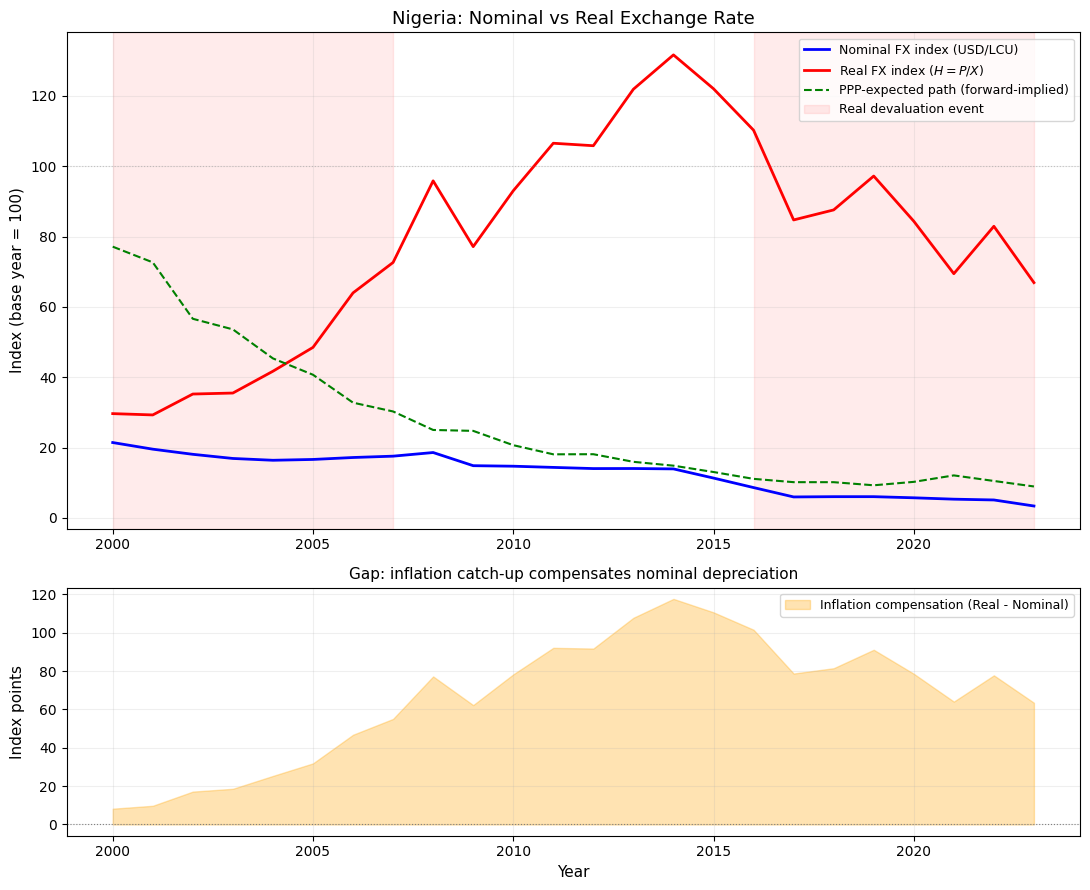


--- Nigeria: Nominal Events (1) ---


,Start_Date,End_Date,Duration,Peak_Devaluation,Drawdown_Area
0,2000,2023,24,-95.081952,-1956.843124



--- Nigeria: Real Events (2) ---


,Start_Date,End_Date,Duration,Peak_Devaluation,Drawdown_Area
0,2000,2007,8,-63.582946,-356.698603
1,2016,2023,8,-43.462956,-222.473462



--- Comparison ---
  Nominal total drawdown: -1957 %-years
  Real total drawdown:    -579 %-years
  Nominal/Real ratio:     3.4x


In [10]:
plot_case_study(decomp, 'NGA', 'Nigeria', events_nominal, events_real)

### 5.2 Kenya

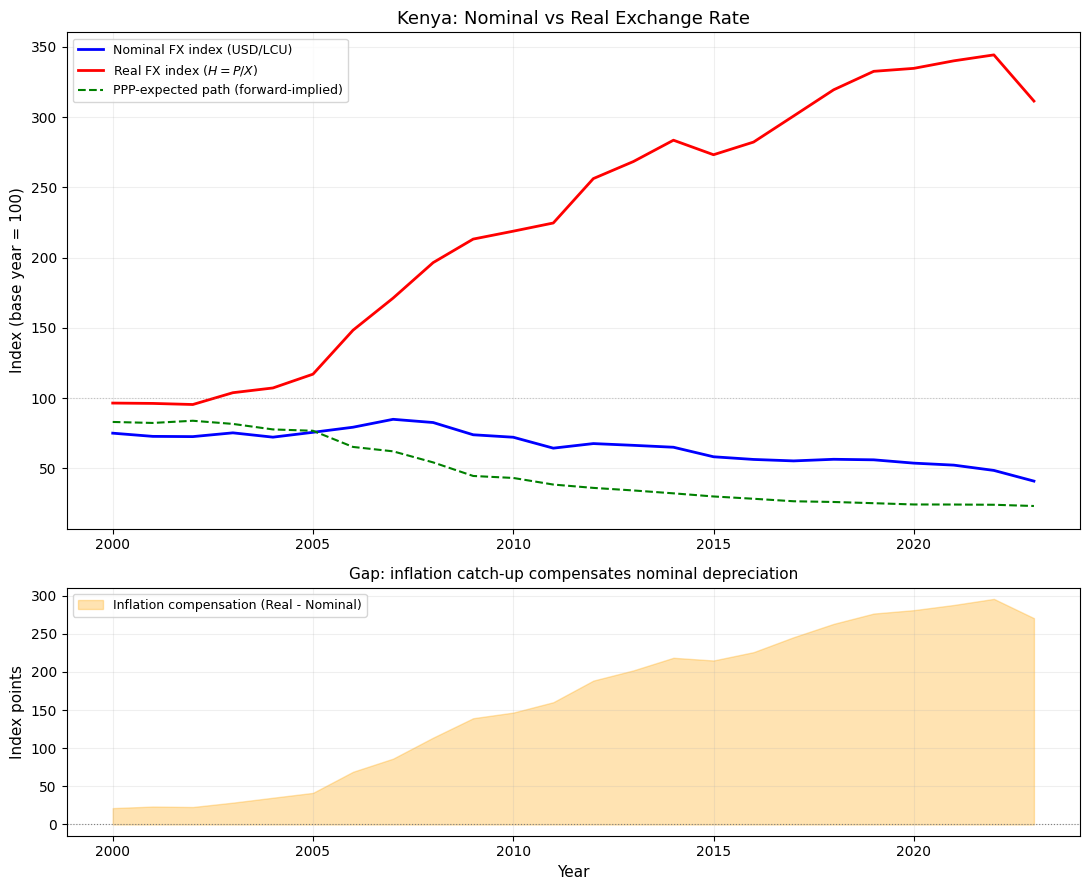


--- Kenya: Nominal Events (2) ---


,Start_Date,End_Date,Duration,Peak_Devaluation,Drawdown_Area
0,2010,2023,14,-47.973369,-365.141039
1,2000,2007,8,-19.497670,-122.385682



--- Kenya: Real Events (0) ---
  No events detected

--- Key finding: 2 nominal event(s) but NO real events ---
  Nominal drawdown: -488 %-years
  Inflation fully compensated the nominal devaluation.


In [11]:
plot_case_study(decomp, 'KEN', 'Kenya', events_nominal, events_real)

### 5.3 Ghana

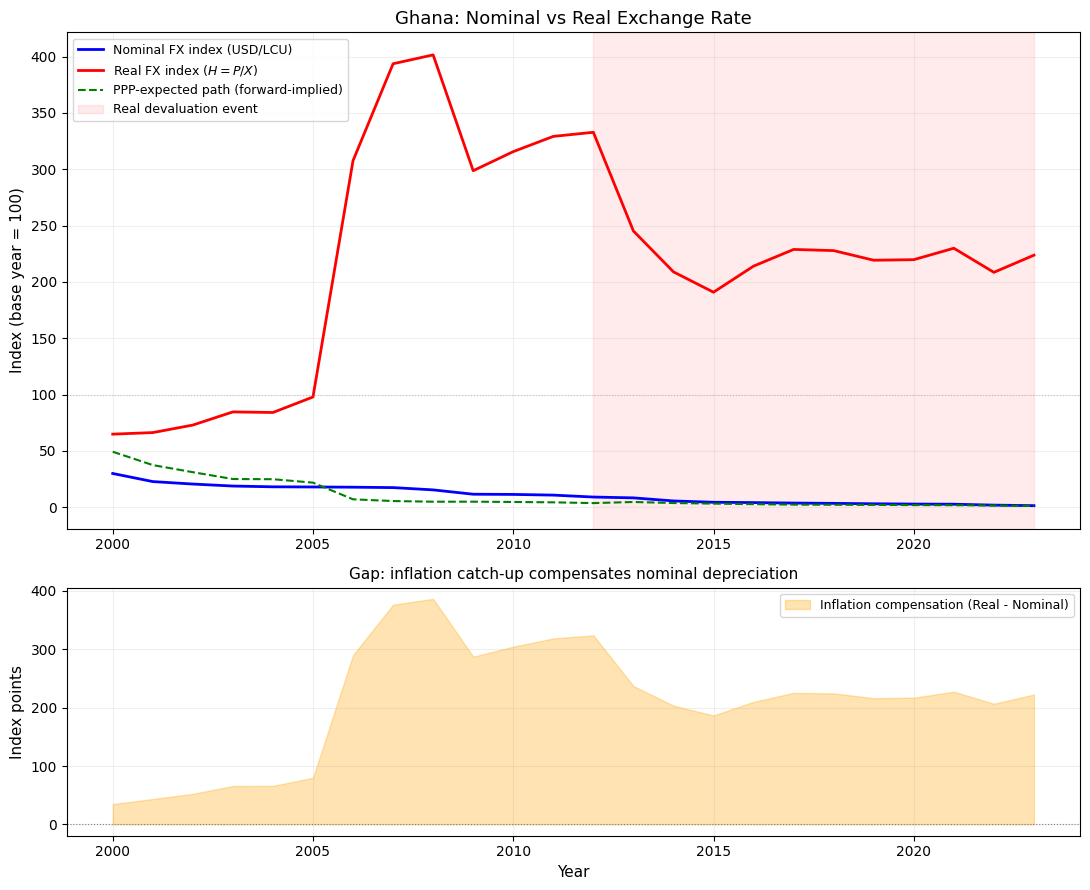


--- Ghana: Nominal Events (1) ---


,Start_Date,End_Date,Duration,Peak_Devaluation,Drawdown_Area
0,2000,2023,24,-97.855691,-2013.424397



--- Ghana: Real Events (1) ---


,Start_Date,End_Date,Duration,Peak_Devaluation,Drawdown_Area
0,2012,2023,12,-37.857916,-380.56249



--- Comparison ---
  Nominal total drawdown: -2013 %-years
  Real total drawdown:    -381 %-years
  Nominal/Real ratio:     5.3x


In [12]:
plot_case_study(decomp, 'GHA', 'Ghana', events_nominal, events_real)

## 6. Summary of all country events: nominal vs real

For completeness, list all detected events under both approaches side by side, highlighting countries where nominal events exist but real events are absent or much smaller.

In [13]:
# Country-level summary
nom_summary = events_nominal.groupby('Country').agg(
    n_events_nominal=('Drawdown_Area', 'count'),
    total_drawdown_nominal=('Drawdown_Area', 'sum'),
    worst_peak_nominal=('Peak_Devaluation', 'min'),
).reset_index()

real_summary = events_real.groupby('Country').agg(
    n_events_real=('Drawdown_Area', 'count'),
    total_drawdown_real=('Drawdown_Area', 'sum'),
    worst_peak_real=('Peak_Devaluation', 'min'),
).reset_index()

country_comp = pd.merge(nom_summary, real_summary, on='Country', how='outer').fillna(0)
country_comp['drawdown_ratio'] = np.where(
    country_comp['total_drawdown_real'] != 0,
    country_comp['total_drawdown_nominal'] / country_comp['total_drawdown_real'],
    np.inf
)
country_comp = country_comp.sort_values('total_drawdown_nominal')

print("=== COUNTRY-LEVEL COMPARISON ===")
print(f"Countries with nominal events: {(country_comp['n_events_nominal'] > 0).sum()}")
print(f"Countries with real events: {(country_comp['n_events_real'] > 0).sum()}")
print(f"Countries with nominal but NO real events: "
      f"{((country_comp['n_events_nominal'] > 0) & (country_comp['n_events_real'] == 0)).sum()}")
print()
display(country_comp.round(1))

=== COUNTRY-LEVEL COMPARISON ===
Countries with nominal events: 49
Countries with real events: 47
Countries with nominal but NO real events: 4



,Country,n_events_nominal,total_drawdown_nominal,worst_peak_nominal,n_events_real,total_drawdown_real,worst_peak_real,drawdown_ratio
8,COD,1.0,-2393.4,-99.9,1.0,-18.4,-10.4,129.8
18,GHA,1.0,-2013.4,-97.9,1.0,-380.6,-37.9,5.3
35,NGA,1.0,-1956.8,-95.1,2.0,-579.2,-63.6,3.4
19,GIN,1.0,-1724.0,-87.2,2.0,-160.1,-36.5,10.8
49,ZMB,1.0,-1680.6,-91.4,1.0,-289.6,-40.8,5.8
1,BDI,1.0,-1602.8,-83.2,1.0,-17.3,-10.9,92.5
39,SLE,1.0,-1591.1,-93.8,1.0,-133.3,-28.6,11.9
20,GMB,1.0,-1544.3,-82.2,2.0,-245.8,-51.2,6.3
29,MOZ,1.0,-1462.5,-80.6,2.0,-345.4,-37.0,4.2
27,MDG,1.0,-1220.2,-75.8,2.0,-45.1,-20.7,27.0


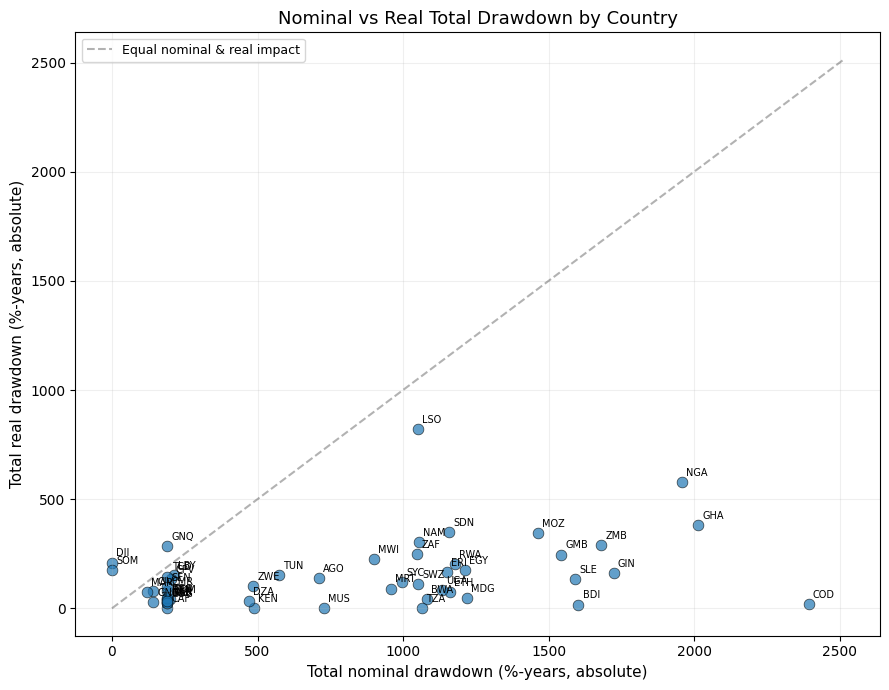

Points below the 45-degree line indicate countries where the real impact
was smaller than the nominal impact (inflation compensation at work).


In [14]:
# Scatter: nominal vs real drawdown by country
plot_data = country_comp[
    (country_comp['total_drawdown_nominal'] != 0) |
    (country_comp['total_drawdown_real'] != 0)
].copy()

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(-plot_data['total_drawdown_nominal'], -plot_data['total_drawdown_real'],
           s=60, alpha=0.7, edgecolors='black', linewidths=0.5)

# Label points
for _, row in plot_data.iterrows():
    ax.annotate(row['Country'], (-row['total_drawdown_nominal'], -row['total_drawdown_real']),
                fontsize=7, ha='left', va='bottom', xytext=(3, 3),
                textcoords='offset points')

# 45-degree line
lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, lim], [0, lim], 'k--', alpha=0.3, label='Equal nominal & real impact')

ax.set_xlabel('Total nominal drawdown (%-years, absolute)', fontsize=11)
ax.set_ylabel('Total real drawdown (%-years, absolute)', fontsize=11)
ax.set_title('Nominal vs Real Total Drawdown by Country', fontsize=13)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('../output/nominal_vs_real_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

print("Points below the 45-degree line indicate countries where the real impact")
print("was smaller than the nominal impact (inflation compensation at work).")